In [1]:
!pip install pandas numpy scikit-learn matplotlib seaborn xgboost shap joblib

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   - -------------------------------------- 1.6/48.9 MB 8.4 MB/s eta 0:00:06
   -- ------------------------------------- 3.4/48.9 MB 8.7 MB/s eta 0:00:06
   ---- ----------------------------------- 5.8/48.9 MB 9.2 MB/s eta 0:00:05
   ------ --------------------------------- 8.1/48.9 MB 9.7 MB/s eta 0:00:05
   -------- ------------------------------- 10.2/48.9 MB 9.9 MB/s eta 0:00:04
   ---------- ----------------------------- 12.6/48.9 MB 10.2 MB/s eta 0:00:04
   ------------ --------------------------- 15.2/48.9 MB 10.5 MB/s eta 0:00:04
   -------------- ------------------------- 17.8/48.9 MB 10.6 MB/s eta 0:00:03
   ---------------- ----------------------- 20.2/48.9 MB 10.6 MB/s eta 0:00:03
   ------------------ --------------------- 22.8/48.9 MB 10.8 MB/s eta 0:00:03
   -------------------- ------------------- 25.2/48.9 MB 10.9 MB/s eta 0:00:03
   ---------------------- ----------------- 27.5/48.9 MB 10.9 MB/s eta

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import shap, joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, accuracy_score)
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

RANDOM_STATE = 42

df = pd.read_csv("data.csv", sep=";")
df.columns = df.columns.str.strip()          # removes the hidden tab in a column name
print(df.shape)
df.head()

(4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


0 missing values
Target
Graduate    0.499
Dropout     0.321
Enrolled    0.179
Name: proportion, dtype: float64


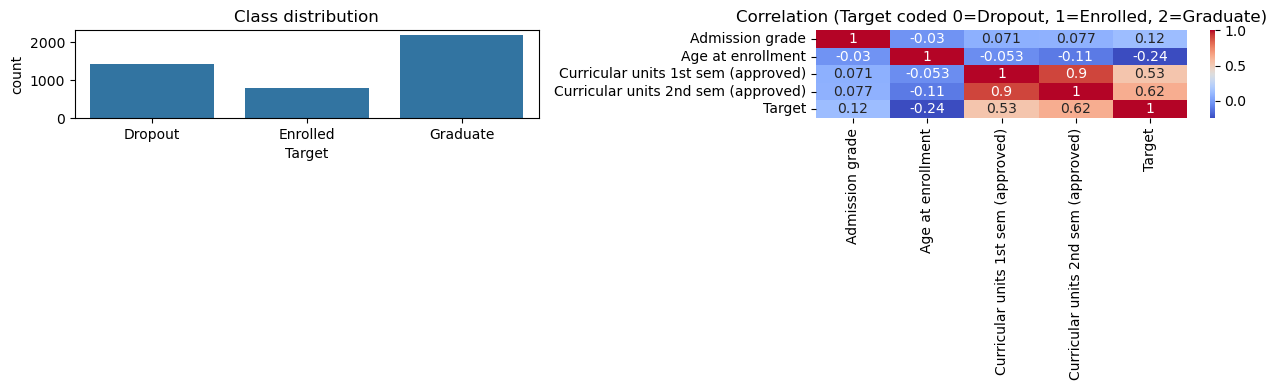

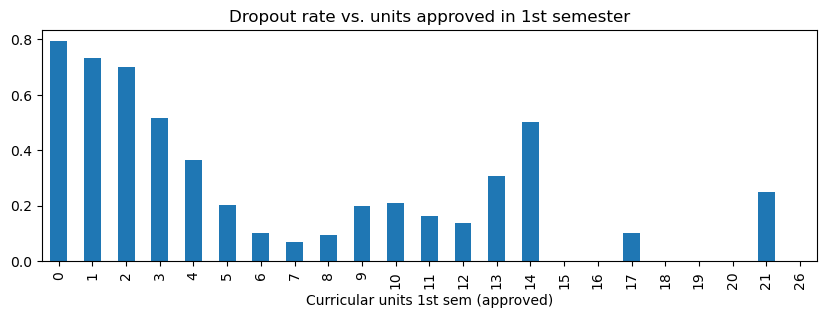

In [3]:
print(df.isna().sum().sum(), "missing values")
print(df["Target"].value_counts(normalize=True).round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=df, x="Target", ax=ax[0], order=["Dropout", "Enrolled", "Graduate"])
ax[0].set_title("Class distribution")

key = ["Admission grade", "Age at enrollment",
       "Curricular units 1st sem (approved)", "Curricular units 2nd sem (approved)"]
sns.heatmap(df[key].assign(Target=df["Target"].astype("category").cat.codes).corr(),
            annot=True, cmap="coolwarm", ax=ax[1])
ax[1].set_title("Correlation (Target coded 0=Dropout, 1=Enrolled, 2=Graduate)")
plt.tight_layout(); plt.show()

# Dropout rate by first-semester approved units
df.groupby("Curricular units 1st sem (approved)")["Target"] \
  .apply(lambda s: (s == "Dropout").mean()).plot(kind="bar", figsize=(10, 3),
  title="Dropout rate vs. units approved in 1st semester"); plt.show()

In [4]:
le = LabelEncoder()
y = le.fit_transform(df["Target"])            # Dropout=0, Enrolled=1, Graduate=2
X = df.drop(columns="Target")
print(dict(zip(le.classes_, le.transform(le.classes_))))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

{'Dropout': np.int64(0), 'Enrolled': np.int64(1), 'Graduate': np.int64(2)}


Logistic Regression  macro-F1: 0.704 ± 0.012
Decision Tree        macro-F1: 0.682 ± 0.014
Random Forest        macro-F1: 0.690 ± 0.017
XGBoost              macro-F1: 0.708 ± 0.015


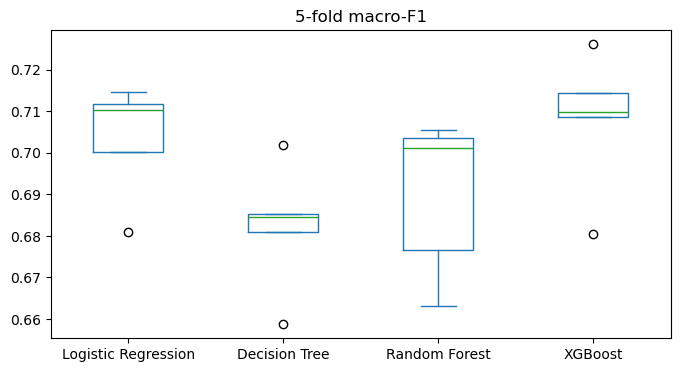

In [5]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(),
        LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, class_weight="balanced",
                                            random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=400, class_weight="balanced",
                                            n_jobs=-1, random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                             subsample=0.8, colsample_bytree=0.8,
                             eval_metric="mlogloss", random_state=RANDOM_STATE),
}

cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
results = {}
for name, m in models.items():
    scores = cross_val_score(m, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
    results[name] = scores
    print(f"{name:20s} macro-F1: {scores.mean():.3f} ± {scores.std():.3f}")

pd.DataFrame(results).plot(kind="box", figsize=(8, 4), title="5-fold macro-F1")
plt.show()

Accuracy: 0.747
Macro F1: 0.711
              precision    recall  f1-score   support

     Dropout       0.84      0.69      0.76       284
    Enrolled       0.45      0.67      0.54       159
    Graduate       0.86      0.81      0.84       442

    accuracy                           0.75       885
   macro avg       0.72      0.72      0.71       885
weighted avg       0.78      0.75      0.76       885



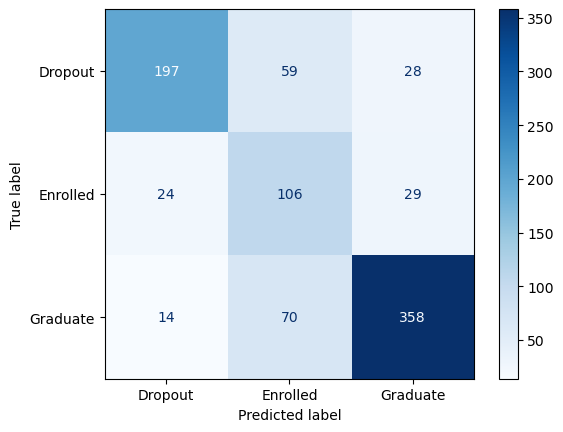

In [6]:
# Sample weights help XGBoost with the smaller "Enrolled" class
weights = compute_sample_weight("balanced", y_train)

final_model = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                            subsample=0.8, colsample_bytree=0.8,
                            eval_metric="mlogloss", random_state=RANDOM_STATE)
final_model.fit(X_train, y_train, sample_weight=weights)

y_pred = final_model.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Macro F1:", round(f1_score(y_test, y_pred, average="macro"), 3))
print(classification_report(y_test, y_pred, target_names=le.classes_))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=le.classes_).plot(cmap="Blues")
plt.show()

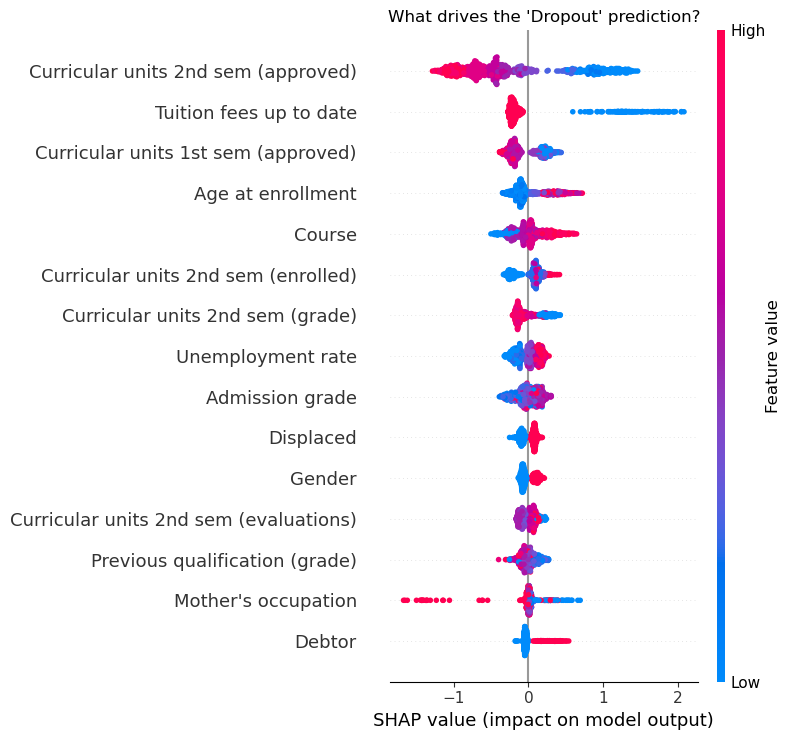

In [7]:
explainer = shap.TreeExplainer(final_model)
sv = explainer.shap_values(X_test)

# Handle different SHAP versions (list vs 3D array)
if isinstance(sv, list):
    sv_dropout = sv[0]
elif sv.ndim == 3:
    sv_dropout = sv[:, :, 0]
else:
    sv_dropout = sv

shap.summary_plot(sv_dropout, X_test, max_display=15, show=False)
plt.title("What drives the 'Dropout' prediction?")
plt.tight_layout(); plt.show()

In [8]:
test_df = X_test.copy()
test_df["y_true"], test_df["y_pred"] = y_test, y_pred
test_df["Age group"] = pd.cut(test_df["Age at enrollment"],
                              [0, 20, 25, 30, 100], labels=["<=20", "21-25", "26-30", "30+"])
test_df["Gender"] = test_df["Gender"].map({0: "Female", 1: "Male"})

def group_report(col):
    rows = []
    for g, d in test_df.groupby(col):
        drop = d[d.y_true == 0]
        rows.append({
            col: g, "n": len(d),
            "accuracy": accuracy_score(d.y_true, d.y_pred),
            "macro_F1": f1_score(d.y_true, d.y_pred, average="macro"),
            "dropout_recall": (drop.y_pred == 0).mean() if len(drop) else np.nan,
            "flagged_as_dropout_%": (d.y_pred == 0).mean(),
        })
    return pd.DataFrame(rows).round(3)

for col in ["Gender", "Scholarship holder", "Age group", "International", "Debtor"]:
    display(group_report(col))

,Gender,n,accuracy,macro_F1,dropout_recall,flagged_as_dropout_%
0,Female,570,0.765,0.721,0.698,0.211
1,Male,315,0.714,0.688,0.690,0.365


,Scholarship holder,n,accuracy,macro_F1,dropout_recall,flagged_as_dropout_%
0,0,680,0.712,0.693,0.702,0.319
1,1,205,0.863,0.711,0.579,0.088


,Age group,n,accuracy,macro_F1,dropout_recall,flagged_as_dropout_%
0,<=20,490,0.741,0.677,0.551,0.157
1,21-25,180,0.733,0.721,0.690,0.272
2,26-30,88,0.682,0.617,0.725,0.477
3,30+,127,0.835,0.765,0.897,0.528


,International,n,accuracy,macro_F1,dropout_recall,flagged_as_dropout_%
0,0,861,0.749,0.713,0.698,0.265
1,1,24,0.667,0.639,0.556,0.292


,Debtor,n,accuracy,macro_F1,dropout_recall,flagged_as_dropout_%
0,0,771,0.744,0.702,0.643,0.218
1,1,114,0.763,0.714,0.873,0.588


In [11]:
import pickle
from sklearn.metrics import confusion_matrix, classification_report

artifact = {
    "model": final_model,
    "label_encoder": le,
    "class_names": list(le.classes_),
    "features": list(X.columns),
    "defaults": X_train.median().to_dict(),
    "ranges": {c: (float(X_train[c].min()), float(X_train[c].max())) for c in X.columns},
    "metrics": {
        "accuracy": float(accuracy_score(y_test, y_pred)),
        "macro_f1": float(f1_score(y_test, y_pred, average="macro")),
        "n_train": int(len(X_train)),
        "n_test": int(len(X_test)),
    },
    "confusion_matrix": confusion_matrix(y_test, y_pred).tolist(),
    "per_class": classification_report(y_test, y_pred,
                                       target_names=le.classes_, output_dict=True),
}

with open("dropout_model.pkl", "wb") as f:
    pickle.dump(artifact, f)
print("Saved dropout_model.pkl")

Saved dropout_model.pkl


In [12]:
with open("dropout_model.pkl", "rb") as f:
    loaded = pickle.load(f)

print(loaded["class_names"])
print(loaded["metrics"])
print(len(loaded["features"]), "features")

['Dropout', 'Enrolled', 'Graduate']
{'accuracy': 0.7468926553672316, 'macro_f1': 0.7108986201841964, 'n_train': 3539, 'n_test': 885}
36 features
